In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as opt
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [19]:
batch_size = 512
device = torch.device("cpu")

In [20]:
trainloader = torch.utils.data.DataLoader(datasets.MNIST('data', train=True, download=True,
              transform=transforms.Compose([transforms.ToTensor()])), batch_size=batch_size, shuffle=True)
testloader = torch.utils.data.DataLoader(datasets.MNIST('data', train=False, download=True,
              transform=transforms.Compose([transforms.ToTensor()])), batch_size=batch_size, shuffle=True)

print("训练数据形状:", trainloader.dataset.data.shape)
print("测试数据形式:", testloader.dataset.data.shape)

训练数据形状: torch.Size([60000, 28, 28])
测试数据形式: torch.Size([10000, 28, 28])


In [21]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, 5, padding=2) # 输入通道1，输出通道6，卷积核5x5
        self.conv2 = nn.Conv2d(6, 16, 5) # 输入通道6，输出通道16，卷积核5x5
        self.fc1 = nn.Linear(16 * 5 * 5, 120) # 全连接层，输入16*5*5，输出120
        self.fc2 = nn.Linear(120, 84) # 全连接层，输入120，输出84
        self.clf = nn.Linear(84, 10) # 分类层，输入84，输出10

    def forward(self, x):
        # conv1
        x = self.conv1(x)
        # 激活函数sigmoid()
        x = F.sigmoid(x)
        # 平均池化层，kernel=2x2，步长2
        x = F.avg_pool2d(x, kernel_size=2, stride=2)
        
        # conv2
        x = self.conv2(x)
        # 激活函数sigmoid()
        x = F.sigmoid(x)
        # 平均池化层，2x2，步长2
        x = F.avg_pool2d(x, kernel_size=2, stride=2)
        
        # 展开，从第1维开始展开
        x = x.view(x.size(0), -1)
        
        # 全连接层1
        x = self.fc1(x)
        # 激活函数sigmoid()
        x = F.sigmoid(x)
        # 全连接层2
        x = self.fc2(x)
        # 激活函数sigmoid()
        x = F.sigmoid(x)
        
        # 分类层
        x = self.clf(x)
        return x

model = Net().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-2)
model

Net(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (clf): Linear(in_features=84, out_features=10, bias=True)
)

In [22]:
epochs = 30
accs, losses = [], []
for epoch in range(epochs):
    model.train()
    for batch_idx, (x, y) in enumerate(trainloader):
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = F.cross_entropy(out, y)
        loss.backward()
        optimizer.step()

    correct = 0
    testloss = 0
    with torch.no_grad():
        for batch_idx, (x, y) in enumerate(testloader):
            x, y = x.to(device), y.to(device)
            out = model(x)
            testloss += F.cross_entropy(out, y).item()
            pred = out.max(dim=1)[1]
            correct += pred.eq(y).sum().item()

    acc = correct / len(testloader.dataset)
    testloss /= (batch_idx + 1)
    accs.append(acc)
    losses.append(testloss)
    print('epoch:{}, loss:{:.4f}, acc:{:.4f}'.format(epoch, testloss, acc))

epoch:0, loss:2.3010, acc:0.1135
epoch:1, loss:1.0935, acc:0.5945
epoch:2, loss:0.2087, acc:0.9341
epoch:3, loss:0.0995, acc:0.9698
epoch:4, loss:0.0766, acc:0.9763
epoch:5, loss:0.0705, acc:0.9777
epoch:6, loss:0.0551, acc:0.9827
epoch:7, loss:0.0460, acc:0.9867
epoch:8, loss:0.0430, acc:0.9862
epoch:9, loss:0.0480, acc:0.9843
epoch:10, loss:0.0495, acc:0.9840
epoch:11, loss:0.0375, acc:0.9884
epoch:12, loss:0.0467, acc:0.9870
epoch:13, loss:0.0372, acc:0.9879
epoch:14, loss:0.0358, acc:0.9899
epoch:15, loss:0.0336, acc:0.9889
epoch:16, loss:0.0347, acc:0.9886
epoch:17, loss:0.0396, acc:0.9891
epoch:18, loss:0.0324, acc:0.9902
epoch:19, loss:0.0346, acc:0.9895
epoch:20, loss:0.0431, acc:0.9883
epoch:21, loss:0.0362, acc:0.9899
epoch:22, loss:0.0377, acc:0.9893
epoch:23, loss:0.0376, acc:0.9896
epoch:24, loss:0.0376, acc:0.9897
epoch:25, loss:0.0482, acc:0.9868
epoch:26, loss:0.0389, acc:0.9904
epoch:27, loss:0.0385, acc:0.9902
epoch:28, loss:0.0419, acc:0.9891
epoch:29, loss:0.0372, a

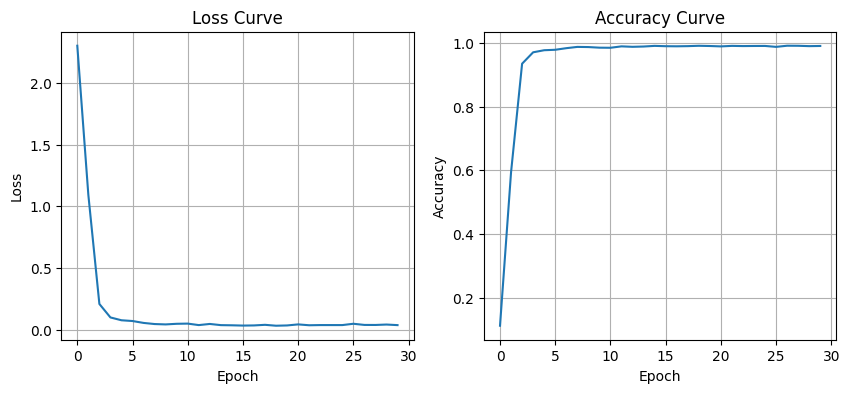

In [23]:
# 可视化
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(losses, label='Loss')
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()

plt.subplot(1,2,2)
plt.plot(accs, label='Acc')
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid()

plt.show()

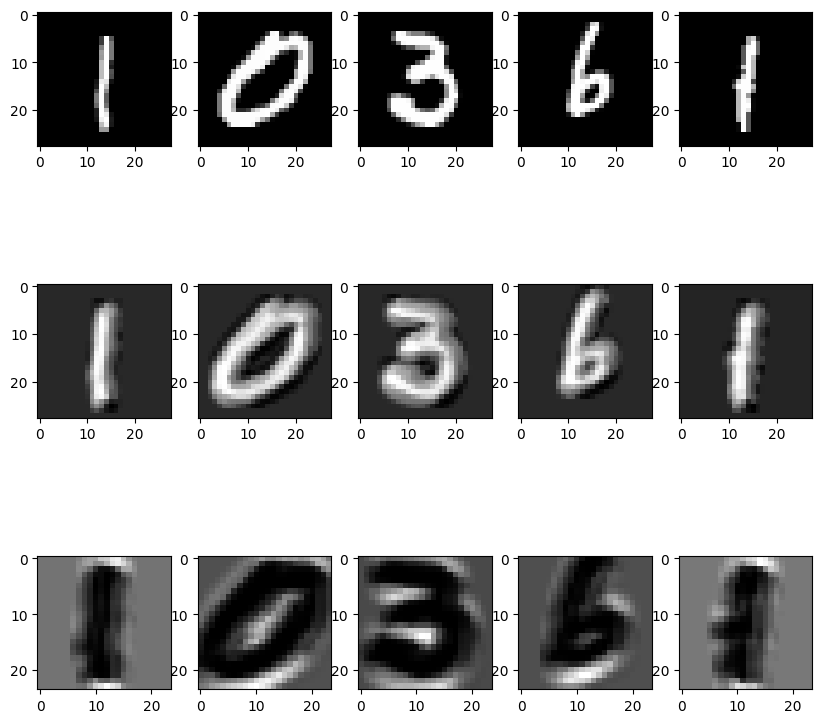

In [24]:
feature1 = F.sigmoid(model.conv1(x))
# feature1 = F.avg_pool2d(feature1,kernel_size=2,stride=2)
feature2 = F.sigmoid(model.conv2(feature1))
# feature2 = F.avg_pool2d(feature2,kernel_size=2,stride=2)

n = 5
img = x.detach().cpu().numpy()[:n]
feature_map1 = feature1.detach().cpu().numpy()[:n]
feature_map2 = feature2.detach().cpu().numpy()[:n]

fig, ax = plt.subplots(3, n, figsize=(10,10))
for i in range(n):
    ax[0,i].imshow(img[i].sum(0),cmap='gray')
    # ax[0,i].axis('off')
    ax[1,i].imshow(feature_map1[i].sum(0),cmap='gray')
    # ax[1,i].axis('off')
    ax[2,i].imshow(feature_map2[i].sum(0),cmap='gray')
    # ax[1,i].axis('off')
plt.show()